In [1]:
from dglgc_funcs import update_glycogen, table1, table2
from dglgc_funcs import get_values
import cobra
import numpy as np
import pandas as pd
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt
%matplotlib inline

ModuleNotFoundError: No module named 'cobra'

In [ ]:

syn6803 = cobra.io.read_sbml_model(
    "/home/hoeper/Models/Synechocystis6803_memote/syn6803/Synechocystis_6803_constrained.xml"
)
universal = cobra.io.read_sbml_model(
    "../models_sbml/universal_model/universal_model_io.sbml"
)

No objective coefficients in model. Unclear what should be optimized


In [ ]:
(gua := universal.metabolites.get_by_id("M02035_c")).formula = "CH6N3"
gua.charge = 1
(ethe:= universal.metabolites.get_by_id("ethe_c")).formula = "C2H4"

efe_tomas = cobra.core.Reaction("EFE")
efe_tomas.name = "Ethylene Forming Enzyme (Tomas)"
efe_tomas.add_metabolites({
    syn6803.metabolites.get_by_id("akg_c"): -10,
    syn6803.metabolites.get_by_id("arg__L_c"): -3,
    syn6803.metabolites.get_by_id("o2_c"): -10,
    syn6803.metabolites.get_by_id("h_c"): -11,
    syn6803.metabolites.get_by_id("co2_c"): 24,
    universal.metabolites.get_by_id("ethe_c"): 7,
    syn6803.metabolites.get_by_id("succ_c"): 3,
    universal.metabolites.get_by_id("M02035_c"): 3,  # guanidine
    syn6803.metabolites.get_by_id("1pyr5c_c"): 3,
    syn6803.metabolites.get_by_id("h2o_c"): 10
})

gdmh = cobra.core.Reaction("GDMH")
gdmh.name = "Guanidine hydrolase "
gdmh.add_metabolites({
    syn6803.metabolites.get_by_id("h2o_c"): -1,
    universal.metabolites.get_by_id("M02035_c"): -1,  # Guanidine
    syn6803.metabolites.get_by_id("nh4_c"): 1,
    syn6803.metabolites.get_by_id("urea_c"): 1
})

syn6803.add_reactions([efe_tomas, gdmh])

In [ ]:
met_dict = {
    "Glycogen": ("glycogen_c", None),
    "Pyruvate": ("pyr_c", None),
    "Succinate": ("succ_c", None),
    "2-Oxoglutarate": ("akg_c", None),
    "Fumarate": ("fum_c", None),
    "Malate": ("mal__L_c", None),
    "Citrate": ("cit_c", None),
    "Lipid": ("palmACP_c", "ACP_c"),
    "Lipid elongation": ("palmACP_c", "myrsACP_c"),
    "Additional double bond": ("hdeceACP_c", "palmACP_c"),
    "Protein (per AA)": ("bm_pro_c", None),
    "Ethylene": ("ethe_c", None)
}

In [ ]:
rows = []
for name, (moi, add_m) in met_dict.items():
    row = table1(syn6803, name, moi, add_m)
    rows.append(row)

table1_df = pd.DataFrame(rows)

print(table1_df.to_string(index=False))

            Metabolite  C atoms  ATP demand  NADPH demand  ATP/NADPH    Photons
              Glycogen        6   18.000000     12.750000   1.411765  51.000000
              Pyruvate        3    7.000000      5.100000   1.372549  20.916667
             Succinate        4   14.000000      7.200000   1.944444  34.333333
        2-Oxoglutarate        5   14.000000      8.200000   1.707317  36.833333
              Fumarate        4    8.000000      6.200000   1.290323  24.833333
                Malate        4    8.000000      6.200000   1.290323  24.833333
               Citrate        6   14.000000      9.300000   1.505376  39.583333
                 Lipid       16   55.000000     46.000000   1.195652 184.000000
      Lipid elongation       16    7.000000      6.000000   1.166667  24.000000
Additional double bond       16    0.857143      0.142857   6.000000   4.000000
      Protein (per AA)        0   18.307154      8.661486   2.113627  63.571085
              Ethylene        2   18.285

In [ ]:

syn6803 = cobra.io.read_sbml_model(
    "/home/hoeper/Models/Synechocystis6803_memote/syn6803/Synechocystis_6803_constrained.xml"
)
syn6803.add_reactions([efe_tomas, gdmh])

In [ ]:

growth_WT = 0.048681058969584315
light_WT = 200
glycogen_WT = 13.7936

In [ ]:
# generate the WT solution
growth_85 = growth_WT * (100-glycogen_WT)/100
with syn6803:
    syn6803.objective = "EX_photon_e1_e"
    syn6803.add_boundary(syn6803.metabolites.get_by_id("bm_glycogen_c"), type="demand")
    
    syn6803.reactions.get_by_id("EX_biomass_e").lower_bound = growth_85
    syn6803.reactions.get_by_id("DM_bm_glycogen_c").lower_bound = growth_WT * glycogen_WT/100  # * glycogen_mol
    syn6803 = update_glycogen(syn6803, 0)
    solution_WT = syn6803.optimize()
    PHOTONS_WT = solution_WT.objective_value
    glycogen_flux_WT = solution_WT.fluxes["BM0010"] * -syn6803.reactions.BM0010.metabolites[syn6803.metabolites.glycogen_c]
    
    nadph_WT, atp_WT, C_uptake_WT, N_uptake_WT, _, _ = get_values(syn6803, None)

print(f"target ATP/NADPH value: {atp_WT/nadph_WT}")

target ATP/NADPH value: 2.0500578710760697


In [ ]:
low_glycogen = glycogen_WT * 0.5

LGS_strain = syn6803.copy()

LGS_strain.add_boundary(LGS_strain.metabolites.get_by_id("bm_glycogen_c"), type="demand")
LGS_glycogen_constraint = LGS_strain.problem.Constraint(
    ((100-low_glycogen)/low_glycogen) * LGS_strain.reactions.get_by_id("DM_bm_glycogen_c").flux_expression- LGS_strain.reactions.get_by_id("EX_biomass_e").flux_expression,
    lb=0,
    ub=0,
    name="LGS_glycogen_constraint"
)
LGS_strain.add_cons_vars(LGS_glycogen_constraint)
LGS_strain = update_glycogen(LGS_strain, 0)

LGS_growth = 0.0479595961923382

In [ ]:
D_glgc_strain = syn6803.copy()
D_glgc_strain = update_glycogen(D_glgc_strain, 0)

D_glgc_growth = 0.04263315582429489

In [ ]:
D_glgc_efe_strain = syn6803.copy()
eth_EFE = 0.04083758588634332
D_glgc_efe_strain.add_boundary(D_glgc_efe_strain.metabolites.get_by_id("ethe_c"), type="demand")
D_glgc_efe_strain.reactions.get_by_id("DM_ethe_c").lower_bound = eth_EFE
D_glgc_efe_strain = update_glycogen(D_glgc_efe_strain, 0)

D_glgc_efe_growth = 0.03604767385740589

In [ ]:
export_dict = {
    "Pyruvate": "pyr_c",
    "2-Oxoglutarate": "akg_c",
    "Fumerate": "fum_c",
    "Succinate": "succ_c",
    "Ribose-5-phosphate": "r5p_c",
    "Ethylene": "ethe_c"
}

In [ ]:
met_rows = []
for name, moi in export_dict.items():
    row = table2(D_glgc_strain, name, moi, PHOTONS_WT, growth_WT, atp_WT/nadph_WT)
    met_rows.append(row)

met_table = pd.concat(met_rows, axis=1).T

print(met_table.to_string(index=False))

        Metabolite Extracellular flux Growth rate (1/h) Growth rate (% of WT)       C:N Carbon loss (mmol C gDW-1 h-1)
          Pyruvate           0.086594          0.042561             87.428295  5.142699                       0.259783
    2-Oxoglutarate           0.106805          0.038769             79.639391  5.945266                       0.534026
          Fumerate           0.065928          0.042872             88.066958  5.147655                       0.263711
         Succinate           0.272489          0.029227             60.038022  8.405926                       1.089957
Ribose-5-phosphate           0.060301          0.041039             84.301865  5.272759                       0.301507
          Ethylene           0.238624          0.027082             55.632223  6.347835                       0.477247


In [ ]:
met_rows = []
for name, moi in export_dict.items():
    row = table2(LGS_strain, name, moi, PHOTONS_WT, growth_WT, atp_WT/nadph_WT, low_glycogen)
    met_rows.append(row)
met_table = pd.concat(met_rows, axis=1).T

print(met_table.to_string(index=False))

lgs_table = met_table.copy()

        Metabolite Extracellular flux Growth rate (1/h) Growth rate (% of WT)       C:N Carbon loss (mmol C gDW-1 h-1)
          Pyruvate           0.046201          0.045416             93.292525  5.138215                       0.138604
    2-Oxoglutarate           0.059455          0.043163             88.665844  5.569224                       0.297276
          Fumerate           0.035055          0.045592             93.654897  5.140876                       0.140222
         Succinate           0.178075          0.036109             74.173685  7.012099                         0.7123
Ribose-5-phosphate           0.032719          0.044535             91.482379  5.208062                       0.163594
          Ethylene           0.153325          0.034803             71.491908  5.785419                       0.306651


In [ ]:

print(lgs_table.loc[0]["C:N"])

5.138214838152218


In [ ]:
met_rows = []
for name, moi in list(export_dict.items())[:-1]:
    row = table2(D_glgc_efe_strain, name, moi, PHOTONS_WT, growth_WT, atp_WT/nadph_WT)
    met_rows.append(row)

met_table = pd.concat(met_rows, axis=1).T

print(met_table.to_string(index=False))

        Metabolite Extracellular flux Growth rate (1/h) Growth rate (% of WT)       C:N Carbon loss (mmol C gDW-1 h-1)
          Pyruvate           0.071775          0.039912             81.986774  5.282647                       0.215324
    2-Oxoglutarate           0.088527          0.036769             75.530848  5.996011                       0.442633
          Fumerate           0.054645           0.04017             82.516138  5.286133                        0.21858
         Succinate           0.171584          0.032479             66.717223  6.978178                       0.686337
Ribose-5-phosphate           0.049982          0.038651             79.395395  5.401678                       0.249908


In [ ]:
glyc_rows = []

for x in np.arange(0.1, 1.0, 0.1):

    low_glycogen = glycogen_WT * x

    LGS_strain_sens = syn6803.copy()

    LGS_strain_sens.add_boundary(LGS_strain_sens.metabolites.get_by_id("bm_glycogen_c"), type="demand")
    LGS_glycogen_constraint = LGS_strain_sens.problem.Constraint(
        ((100-low_glycogen)/low_glycogen) * LGS_strain_sens.reactions.get_by_id("DM_bm_glycogen_c").flux_expression- LGS_strain_sens.reactions.get_by_id("EX_biomass_e").flux_expression,
        lb=0,
        ub=0,
        name="LGS_glycogen_constraint"
    )
    LGS_strain_sens.add_cons_vars(LGS_glycogen_constraint)
    LGS_strain_sens = update_glycogen(LGS_strain_sens, 0)

    glyc_rows.append(table2(LGS_strain_sens, "Pyruvate", "pyr_c", PHOTONS_WT, growth_WT, atp_WT/nadph_WT, low_glycogen))



In [ ]:
# divide everything by the LGS values:
for series in glyc_rows:
    series["Extracellular flux"] = 100 - series["Extracellular flux"]/lgs_table.loc[0]["Extracellular flux"] * 100-.5
    series["Growth rate (1/h)"] = 100 - series["Growth rate (1/h)"]/lgs_table.loc[0]["Growth rate (1/h)"] * 100 -.5
    series["Growth rate (% of WT)"] = 100 - series["Growth rate (% of WT)"]/lgs_table.loc[0]["Growth rate (% of WT)"] * 100 + .5
    series["C:N"] = 100 - series["C:N"]/lgs_table.loc[0]["C:N"] * 100
    series["Carbon loss (mmol C gDW-1 h-1)"] = 100 - series["Carbon loss (mmol C gDW-1 h-1)"]/lgs_table.loc[0]["Carbon loss (mmol C gDW-1 h-1)"] * 100+.5


In [ ]:

print(glyc_rows[1])

Metabolite                         Pyruvate
Extracellular flux               -54.309942
Growth rate (1/h)                  3.368786
Growth rate (% of WT)              4.368786
C:N                               -0.053851
Carbon loss (mmol C gDW-1 h-1)   -53.309942
dtype: object


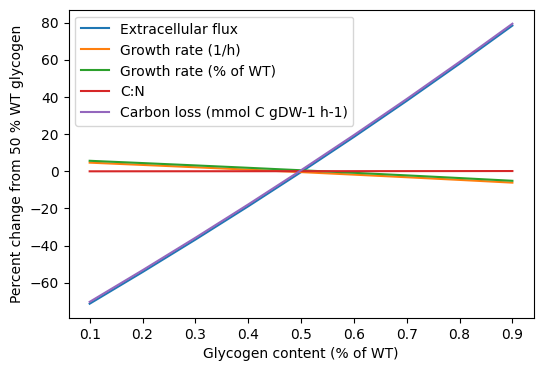

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Extracellular flux"] for row in glyc_rows], label="Extracellular flux")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Growth rate (1/h)"] for row in glyc_rows], label="Growth rate (1/h)")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Growth rate (% of WT)"] for row in glyc_rows], label="Growth rate (% of WT)")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["C:N"] for row in glyc_rows], label="C:N")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Carbon loss (mmol C gDW-1 h-1)"] for row in glyc_rows], label="Carbon loss (mmol C gDW-1 h-1)")
ax.set_xlabel("Glycogen content (% of WT)")
ax.set_ylabel("Percent change from 50 % WT glycogen")
ax.legend()

fig.show()
